# Directional noise bias in DAS (fiber-optic) ambient-noise interferometry

**Question.** Distributed acoustic sensing (DAS) turns a telecom or dedicated fiber into thousands of strain sensors. In a basin, its ambient noise mostly comes from traffic on nearby roads, which is about as directional as noise gets. How biased are the velocities that DAS interferometry measures, and can the cable layout help?

**Why a fiber differs from seismometers.**
1. **Directional sensitivity.** Let $u$ be the scalar field, treated as a displacement potential. A DAS channel measures axial strain $\varepsilon=\partial^2u/\partial s^2$ along the cable, averaged over a gauge length $L$. For a plane wave arriving at angle $\theta$ from the cable, the response is $-(k\cos\theta)^2\,\mathrm{sinc}(kL\cos\theta/2)$. In a correlation of two channels, the noise therefore enters as $B(\theta)\cos^4\theta\,\mathrm{sinc}^2(\cdot)$, not $B(\theta)$.
2. **Instrument bias.** In the stationary-phase formula $\delta t/t = -B''/(2B\,\omega^2t^2)$, the $\cos^4$ factor adds curvature $-4$ at endfire. Even **perfectly isotropic** noise then shifts DAS arrivals late by $\delta t/t = 2/(\omega t)^2$, relative to the geophone (displacement) Green's function.
3. **No beamforming correction.** A straight cable only measures the along-cable slowness $\cos\theta/c$, so it cannot separate azimuth from velocity. The 2D-array correction in `array_correction.ipynb` has no equivalent on a straight fiber.

**Setup** (basin scale, as in the rest of the project): $c$ = 2.2 km/s, noise band centred on 2 Hz ($\lambda$ = 1.1 km), and the 50 m FD grid. The cable is **L-shaped**, with two 6 km legs and channels every 50 m. There is one FD impulse run per cable node (reciprocity), recorded at every noise source. The sources are the far-field ring plus three traffic roads: parallel to the x-leg, perpendicular beyond its end, and oblique. DAS channels are built from the node records with the gauge-length strain operator `strain_matrix` (verified in `verification.ipynb`, Test 5). "Geophone" channels are the raw node records $u$.

**Reference.** Every bias is measured against the geophone correlation for isotropic noise, which is the displacement Green's function verified in `verification.ipynb`. DAS correlations are divided by $(\omega/c)^4$, their endfire amplitude factor, so the two waveforms can be compared. That factor is real and has no phase, so it does not change the picked time.

241 cable nodes, 951 noise sources, FD time 496 s


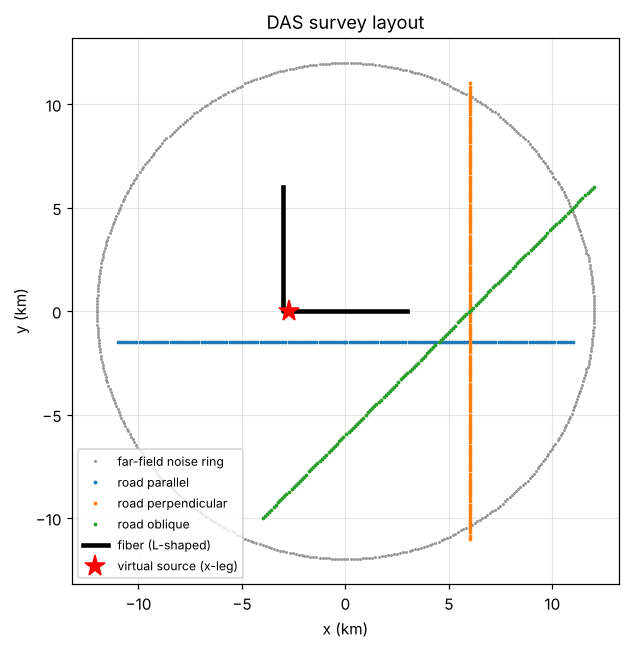

In [1]:
import numpy as np, matplotlib.pyplot as plt, time
import simulation as S
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
fc, gauge = 2.0, 0.2                     # band centre [Hz], gauge length [km]
model = S.Model()
nodes, sources, legs = S.das_layout(model)
t0 = time.time()
F = S.FiberExperiment(model, nodes, sources)        # one FD run per node, in parallel
print(f"{len(nodes)} cable nodes, {len(F.src_xy)} noise sources, FD time {time.time() - t0:.0f} s")

idx = np.arange(len(nodes))
das = F.das_channels(gauge)
xd = np.intersect1d(idx[legs["x-leg"]], das)          # x-leg channels, from the corner outwards
yd = np.intersect1d(idx[legs["y-leg"]], das)[::-1]    # y-leg channels, from the corner outwards
w_iso = F.weights("ring")
names = ["ring", "road parallel", "road perpendicular", "road oblique"]

fig, ax = plt.subplots(figsize=(6, 6))
for n_, col in zip(names, ["0.6", "C0", "C1", "C2"]):
    ax.plot(*F.src_xy[F.groups[n_]].T, ".", ms=2 if n_ == "ring" else 3, color=col,
            label="far-field noise ring" if n_ == "ring" else n_)
ax.plot(*nodes.T, "k-", lw=3, label="fiber (L-shaped)")
ax.plot(*F.xy[xd[0]], "r*", ms=14, label="virtual source (x-leg)")
ax.set(aspect="equal", xlabel="x (km)", ylabel="y (km)", title="DAS survey layout")
ax.legend(fontsize=8, loc="lower left"); plt.tight_layout()

## 1. Isotropic noise: DAS vs geophone
Virtual source at the corner end of the x-leg, receivers along the x-leg.

offset 1.00 km: DAS -7.67 %, theory -5.79 %, geophone -0.00 %
offset 2.00 km: DAS -1.62 %, theory -1.45 %, geophone -0.00 %
offset 3.00 km: DAS -0.72 %, theory -0.64 %, geophone -0.00 %
offset 5.00 km: DAS -0.26 %, theory -0.23 %, geophone -0.00 %


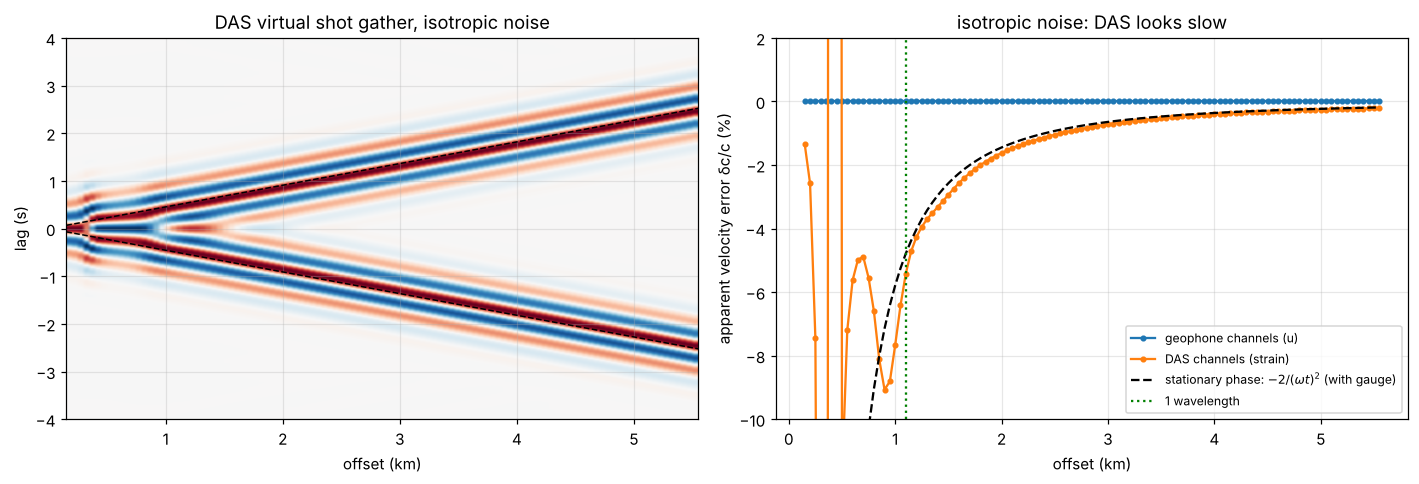

In [2]:
src, ch = xd[0], xd[3:]
off, dv_geo = F.offset_bias(w_iso, "geo", gauge, src, ch, fc, w_ref=w_iso)
_, dv_das = F.offset_bias(w_iso, "das", gauge, src, ch, fc, w_ref=w_iso)
pred = S.das_bias_prediction(off, fc, gauge=gauge)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
G = F.gather(w_iso, "das", gauge, src, ch, fc)
ax[0].imshow((G / np.abs(G).max(1, keepdims=True)).T, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1,
             extent=[off[0], off[-1], F.lags[-1], F.lags[0]])
ax[0].plot(off, off / model.c0, "k--", lw=1); ax[0].plot(off, -off / model.c0, "k--", lw=1)
ax[0].set(ylim=(-4, 4), xlabel="offset (km)", ylabel="lag (s)", title="DAS virtual shot gather, isotropic noise")
ax[1].plot(off, dv_geo, "o-", ms=3, label="geophone channels (u)")
ax[1].plot(off, dv_das, "o-", ms=3, label="DAS channels (strain)")
ax[1].plot(off, pred, "k--", label=r"stationary phase: $-2/(\omega t)^2$ (with gauge)")
ax[1].axvline(model.c0 / fc, color="g", ls=":", label="1 wavelength")
ax[1].set(xlabel="offset (km)", ylabel="apparent velocity error δc/c (%)", ylim=(-10, 2),
          title="isotropic noise: DAS looks slow")
ax[1].legend(fontsize=8); plt.tight_layout()
for o in [1.0, 2.0, 3.0, 5.0]:
    i = np.argmin(np.abs(off - o))
    print(f"offset {off[i]:.2f} km: DAS {dv_das[i]:+.2f} %, theory {pred[i]:+.2f} %, geophone {dv_geo[i]:+.2f} %")

DAS interferometry with *isotropic* noise gives velocities that are too slow: about 6–8% at 1 km offset and 0.7% at 3 km. This agrees with the estimate $2/(\omega t)^2$ and shrinks as $1/\text{offset}^2$. Geophones show no bias, by construction. It is a deterministic instrument effect, because the fiber retrieves a strain-to-strain Green's function rather than the displacement one. So it can be **predicted and subtracted** (Section 5).

## 2. Traffic noise from roads

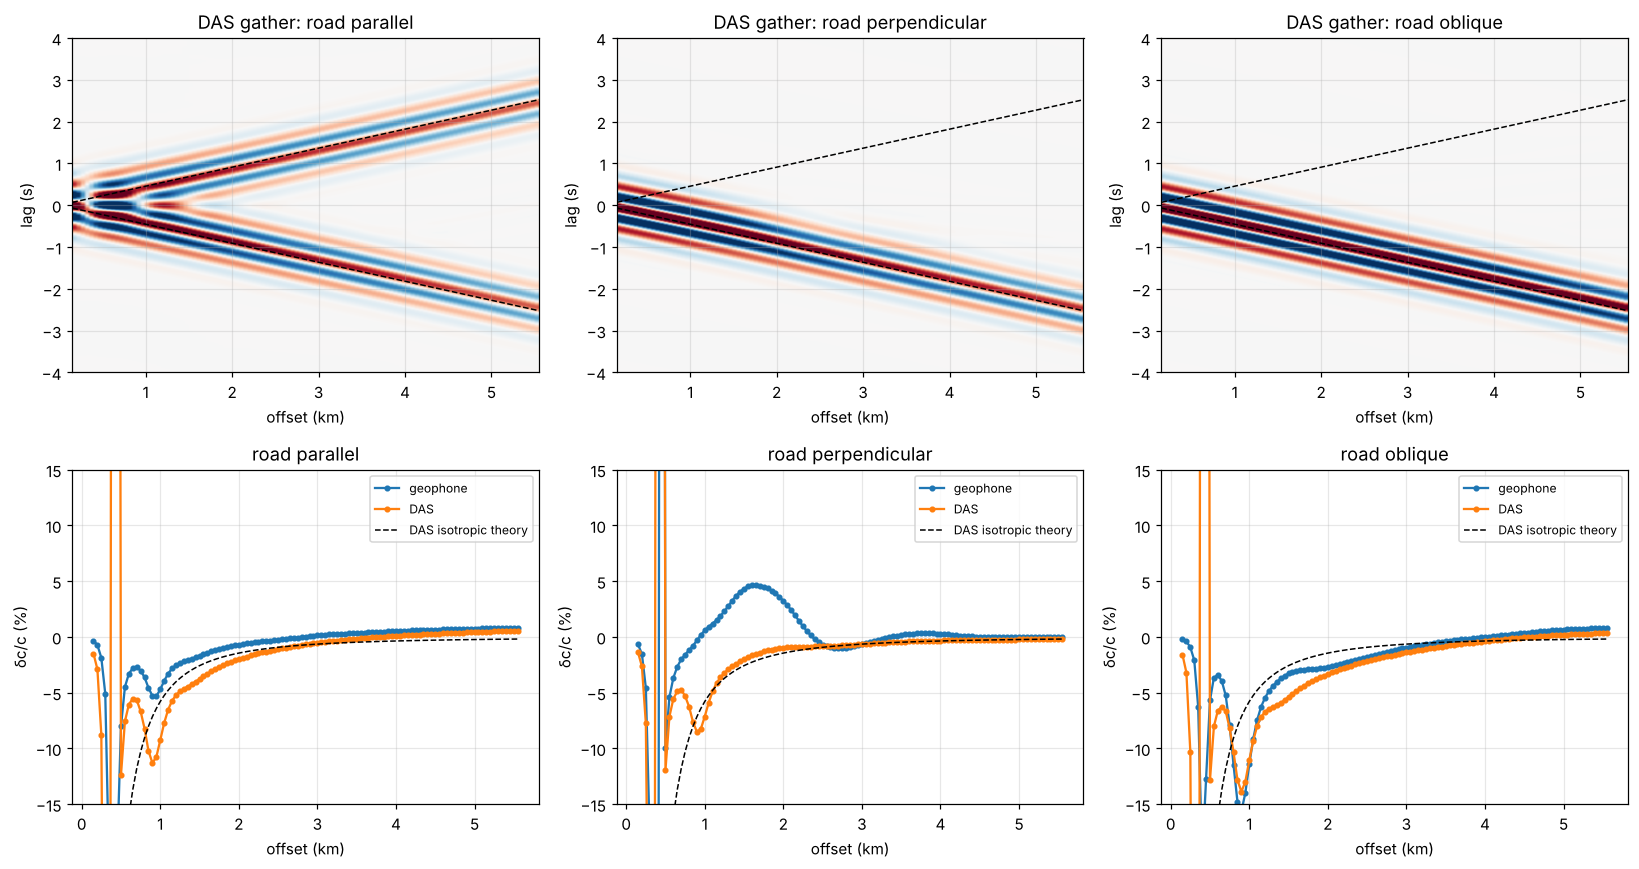

In [3]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
res = {}
for j, n_ in enumerate(names[1:]):
    w = F.weights(n_)
    G = F.gather(w, "das", gauge, src, ch, fc)
    ax[0, j].imshow((G / np.abs(G).max()).T, aspect="auto", cmap="RdBu_r", vmin=-0.5, vmax=0.5,
                    extent=[off[0], off[-1], F.lags[-1], F.lags[0]])
    ax[0, j].plot(off, off / model.c0, "k--", lw=1); ax[0, j].plot(off, -off / model.c0, "k--", lw=1)
    ax[0, j].set(ylim=(-4, 4), xlabel="offset (km)", ylabel="lag (s)", title=f"DAS gather: {n_}")
    for kind in ["geo", "das"]:
        res[n_, kind] = F.offset_bias(w, kind, gauge, src, ch, fc, w_ref=w_iso)[1]
        ax[1, j].plot(off, res[n_, kind], "o-", ms=3, label="geophone" if kind == "geo" else "DAS")
    ax[1, j].plot(off, pred, "k--", lw=1, label="DAS isotropic theory")
    ax[1, j].set(xlabel="offset (km)", ylabel="δc/c (%)", ylim=(-15, 15), title=n_)
    ax[1, j].legend(fontsize=8)
plt.tight_layout()

(Offsets below about one wavelength, 1.1 km, are not meaningful: there, the causal and acausal branches overlap.)
* **Perpendicular road beyond the cable end** (endfire). The gather has one clean branch. DAS follows its isotropic instrument bias almost exactly. Geophones show an error hump of up to +5% at 1–2.5 km offset, caused by the nearby, off-axis parts of the road. The DAS $\cos^4$ sensitivity suppresses those parts.
* **Parallel road** (broadside, 1.5 km away). Both branches are present. Geophone errors go from about −3% at 1 km, through −1% at 2 km, to +0.8% at 5 km. DAS adds its instrument bias on top.
* **Oblique road.** The noise is one-sided and off-axis. It gives the largest systematic error at moderate offsets (about −3% at 2 km for both channel types), which the instrument correction cannot remove.

## 3. Gauge length

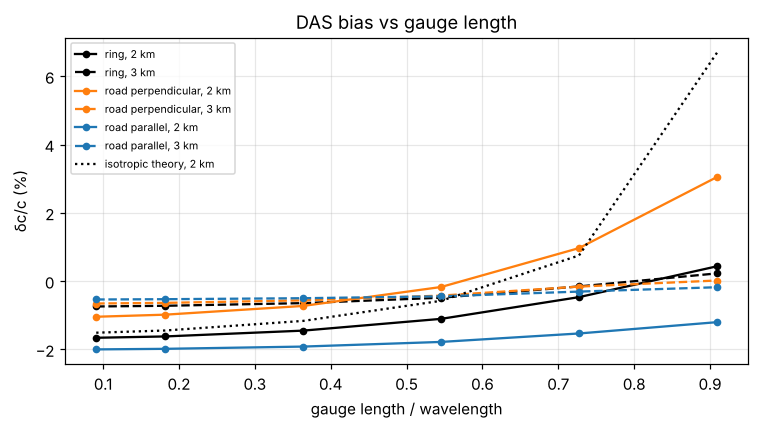

In [4]:
gauges = np.array([0.1, 0.2, 0.4, 0.6, 0.8, 1.0])
fig, ax = plt.subplots(figsize=(7, 4))
for n_, col in [("ring", "k"), ("road perpendicular", "C1"), ("road parallel", "C0")]:
    for o, ls in [(2.0, "-"), (3.0, "--")]:
        vals = []
        for L in gauges:
            dch = F.das_channels(L)
            s_, c_ = np.intersect1d(xd, dch)[0], np.intersect1d(xd, dch)
            off_L, dv_L = F.offset_bias(F.weights(n_), "das", L, s_, c_[3:], fc, w_ref=w_iso)
            vals.append(dv_L[np.argmin(np.abs(off_L - o))])
        ax.plot(gauges * fc / model.c0, vals, "o" + ls, color=col, ms=4, label=f"{n_}, {o:.0f} km")
ax.plot(gauges * fc / model.c0, [S.das_bias_prediction(2.0, fc, gauge=L) for L in gauges], "k:", label="isotropic theory, 2 km")
ax.set(xlabel="gauge length / wavelength", ylabel="δc/c (%)", title="DAS bias vs gauge length")
ax.legend(fontsize=7); plt.tight_layout()

A longer gauge is a spatial low-pass filter, $\mathrm{sinc}(kL\cos\theta/2)$. It is weakest at endfire, so it partly cancels the $\cos^4$ curvature, and the isotropic bias shrinks for gauges that are a sizeable fraction of a wavelength. At the 10–20 m gauges common in practice, $L/\lambda \ll 0.1$ at 2 Hz, so the gauge barely matters. The stationary-phase prediction (dotted) diverges once $L \gtrsim 0.6\lambda$, where the gauge response approaches its first zero, and should not be used there.

## 4. A straight cable cannot separate azimuth from velocity
For a nearly plane wave (a concentrated ring source, $\kappa = 100$) from back-azimuth $\theta_0$, a slant stack along the x-leg measures the along-cable slowness $\cos\theta_0/c$. The apparent velocity is $c/|\cos\theta_0|$, and nothing measured on a straight cable tells you $\theta_0$.

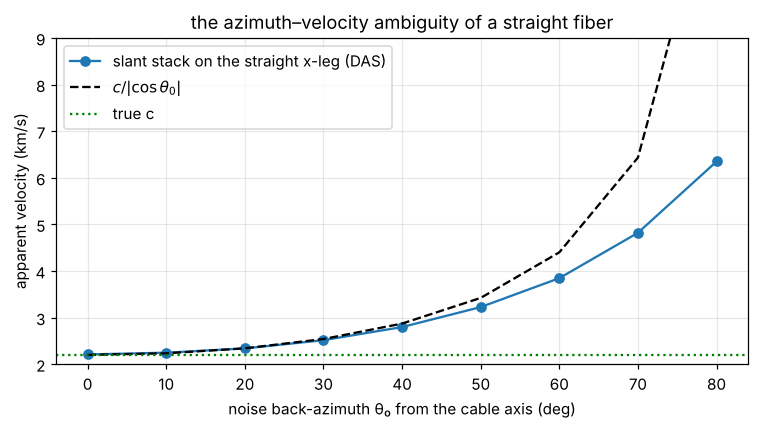

In [5]:
th_ring = np.arctan2(*F.src_xy[F.groups["ring"]][:, ::-1].T)
th0s = np.arange(0, 81, 10)
capp = []
for th0 in th0s:
    w = np.zeros(len(F.src_xy)); w[F.groups["ring"]] = S.source_density(th_ring, np.radians(th0), 100.0)
    capp.append(1 / abs(S.leg_slowness(F, w / w.sum(), xd, 0.0, "das", gauge, fc)))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(th0s, capp, "o-", label="slant stack on the straight x-leg (DAS)")
ax.plot(th0s, model.c0 / np.cos(np.radians(th0s)), "k--", label=r"$c/|\cos\theta_0|$")
ax.axhline(model.c0, color="g", ls=":", label="true c")
ax.set(xlabel="noise back-azimuth θ₀ from the cable axis (deg)", ylabel="apparent velocity (km/s)",
       ylim=(2, 9), title="the azimuth–velocity ambiguity of a straight fiber"); ax.legend()
plt.tight_layout()

The apparent velocity is always *too fast*, and it diverges toward broadside. Near broadside the measured values fall below $c/|\cos\theta_0|$ for two reasons. The along-cable slowness becomes smaller than the cable's slowness resolution ($\sim 1/(fL_\text{cable})$). And the noise ring is only 12 km away, so wavefronts are slightly curved along a 6 km leg.

## 5. Mitigation with the L-shaped cable
A fiber can't beamform its way out, but an L gives two perpendicular legs and therefore two looks at every noise source. A simple, data-only rule:
1. For each leg, compute the virtual-source gather and measure the **branch asymmetry** (causal/acausal energy) at about 2.5 km offset. A strongly one-sided correlation means noise is arriving near that leg's endfire, which is exactly when interferometry works.
2. **Use the leg with the larger |asymmetry|**.
3. **Subtract the deterministic DAS instrument bias** $-2/(\omega t)^2$ (with gauge), since it is known from theory and does not depend on the noise.

ring                 x-leg:  -1.05% ( -0.0 dB)   y-leg:  -1.03% ( -0.0 dB)   -> use x-leg, after instrument correction -0.12%
road parallel        x-leg:  -1.09% ( -2.1 dB)   y-leg:  -0.75% (+64.0 dB)   -> use y-leg, after instrument correction +0.18%


road perpendicular   x-leg:  -0.83% (-68.6 dB)   y-leg: +21.71% ( +6.3 dB)   -> use x-leg, after instrument correction +0.10%


road oblique         x-leg:  -2.17% (-68.8 dB)   y-leg:  -2.46% (+62.6 dB)   -> use x-leg, after instrument correction -1.24%


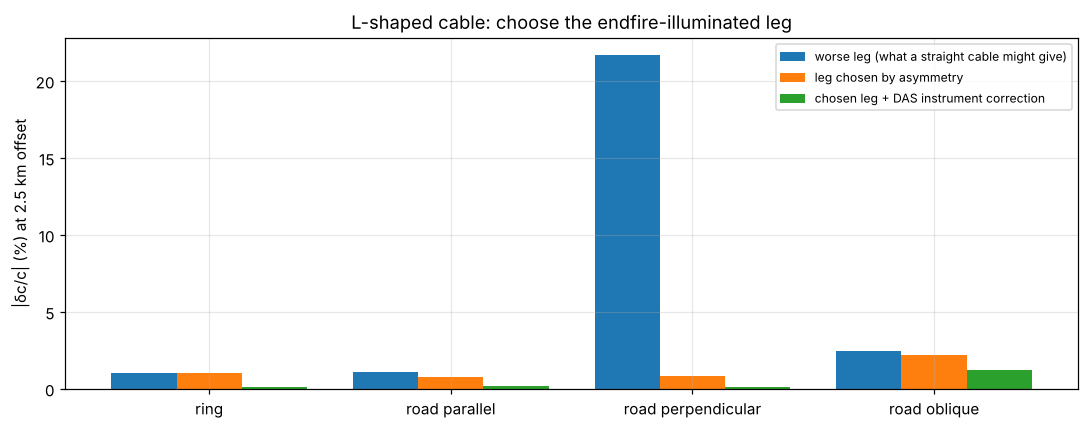

In [6]:
o_sel = 2.5
rows = []
for n_ in names:
    w = F.weights(n_)
    leg_res = {}
    for leg, chs in [("x-leg", xd), ("y-leg", yd)]:
        s_, c_ = chs[0], chs[3:]
        off_l, dv_l = F.offset_bias(w, "das", gauge, s_, c_, fc, w_ref=w_iso)
        i = np.argmin(np.abs(off_l - o_sel))
        C = F.gather(w, "das", gauge, s_, [c_[i]], fc)[0]
        t = off_l[i] / model.c0
        win = lambda sg: np.abs(F.lags - sg * t) < 1.5 / fc
        asym = 10 * np.log10(np.sum(C[win(1)] ** 2) / np.sum(C[win(-1)] ** 2))
        leg_res[leg] = (dv_l[i], asym, off_l[i])
    best = max(leg_res, key=lambda l: abs(leg_res[l][1]))
    corr = leg_res[best][0] - S.das_bias_prediction(leg_res[best][2], fc, gauge=gauge)
    rows.append((n_, leg_res, best, corr))
    print(f"{n_:20s} x-leg: {leg_res['x-leg'][0]:+6.2f}% ({leg_res['x-leg'][1]:+5.1f} dB)   "
          f"y-leg: {leg_res['y-leg'][0]:+6.2f}% ({leg_res['y-leg'][1]:+5.1f} dB)   "
          f"-> use {best}, after instrument correction {corr:+.2f}%")

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(rows))
worst = [max(abs(r[1]["x-leg"][0]), abs(r[1]["y-leg"][0])) for r in rows]
ax.bar(x - 0.27, worst, 0.27, label="worse leg (what a straight cable might give)")
ax.bar(x, [abs(r[1][r[2]][0]) for r in rows], 0.27, label="leg chosen by asymmetry")
ax.bar(x + 0.27, [abs(r[3]) for r in rows], 0.27, label="chosen leg + DAS instrument correction")
ax.set_xticks(x, [r[0] for r in rows]); ax.set(ylabel="|δc/c| (%) at 2.5 km offset",
       title="L-shaped cable: choose the endfire-illuminated leg"); ax.legend(fontsize=8)
plt.tight_layout()

## 6. Contrast: what a 2D station array can do
`array_correction.ipynb` shows that a 25-station 2D array can **beamform** the noise, invert for $B(\theta)$, and correct every pair. With about 8 hours of noise, this cuts the fake azimuthal anisotropy from about 0.9% to about 0.1%. A straight fiber has no access to $\theta$ (Section 4), so that route is closed. The L-shaped cable recovers part of the benefit through leg selection, while keeping the fiber's dense spatial sampling.

## Summary
* **DAS has a built-in bias.** Even with isotropic noise, strain-channel interferometry looks slow by about $2/(\omega t)^2$. The FD result is 7.7% at 1 km offset (theory 5.8%; the formula is only approximate below about one wavelength), 1.6% at 2 km and 0.7% at 3 km, at 2 Hz. It is deterministic, so it can be subtracted.
* **Traffic noise.** An endfire road is benign for DAS. A broadside road gives offset-dependent errors of a few percent. An oblique road gives the largest systematic error that cannot be corrected.
* **A straight cable is blind to azimuth.** Its slant-stack velocity is $c/|\cos\theta|$.
* **An L-shaped cable plus a simple asymmetry rule** picks the leg with endfire illumination. It avoids the +22% error of the broadside leg in the perpendicular-road case. Together with the instrument correction, the error falls to 0.1–0.2% for the isotropic, parallel and perpendicular cases. The oblique road is the exception (−1.2%), because neither leg is close to endfire.
* **Limitations.** This is a scalar wave model, with strain as $\partial_s^2$ of a potential (P/Rayleigh-like). There is no surface-wave dispersion and no realistic fiber coupling. Correlations are expected values (infinite recording), and roads have uniform traffic.